In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
df = pd.read_csv('data/inp_errs_probs.csv')

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_pipeline_error_probabilities_seaborn(
    res,
    num_traces,
    stages=None,
    figsize=(12, 8),
    yscale='symlog',
    xlabel='Layer',
    ylabel='Input Error Probability',
    legend_title='',
    save_name = 'input_err_prob',
    linthresh=1e-5,
    linscale=1.0,
    eps=1e-8,
    font_size=20,
):
    """
    Same function, same inputs.
    Change: different MARKER SHAPE per trace-count curve.
    Legend stays as-is.
    """
    if stages is None:
        stages = [
            'conv1', 'ReLU', 'BN',
            'conv2', 'ReLU', 'BN', 'MaxPool',
            'conv3', 'ReLU', 'BN',
            'conv4', 'ReLU', 'BN', 'MaxPool',
            'conv5', 'ReLU', 'BN',
            'conv6', 'ReLU', 'BN', 'MaxPool',
            'fc1',   'ReLU'
        ]

    sns.set_theme(style="whitegrid")

    fig, ax = plt.subplots(figsize=figsize)

    # unique markers per curve
    marker_cycle = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "H", "p", "8", "+", "x"]
    markers = [marker_cycle[i % len(marker_cycle)] for i in range(len(num_traces))]

    for (counts, label, mk) in zip(res, num_traces, markers):
        y = np.array(counts, dtype=float) + eps
        x = np.arange(len(y))
        sns.lineplot(
            x=x, y=y,
            marker=mk,               # <-- changed
            linewidth=2,
            label=f"{label}k",
            ax=ax,
            markersize=18
        )

    ax.set_yscale(yscale, linthresh=linthresh, linscale=linscale)

    ax.set_xlabel(xlabel, fontsize=font_size)
    ax.set_ylabel(ylabel, fontsize=font_size)
    ax.set_xticks(np.arange(len(stages)))
    ax.set_xticklabels(stages, rotation=-70, ha='center', fontsize=font_size)
    ax.tick_params(axis='y', labelsize=font_size)

    ax.legend(title=legend_title, fontsize=font_size, title_fontsize=font_size)

    ax.grid(True)
    ax.set_ylim(bottom=-1e-6, top=1)

    plt.tight_layout()
    plt.savefig(f"../plots/{save_name}.pdf",
                format="pdf",
                bbox_inches="tight",
                metadata={"Creator": "Matplotlib"})
    plt.show()
    

In [4]:
num_traces = [2, 4, 6, 10, 30]
res_HD = [df[(df.leakage == 'HD') & (df.traces_k == k)].sort_values('stage_idx')['err_prob'].tolist() for k in num_traces]

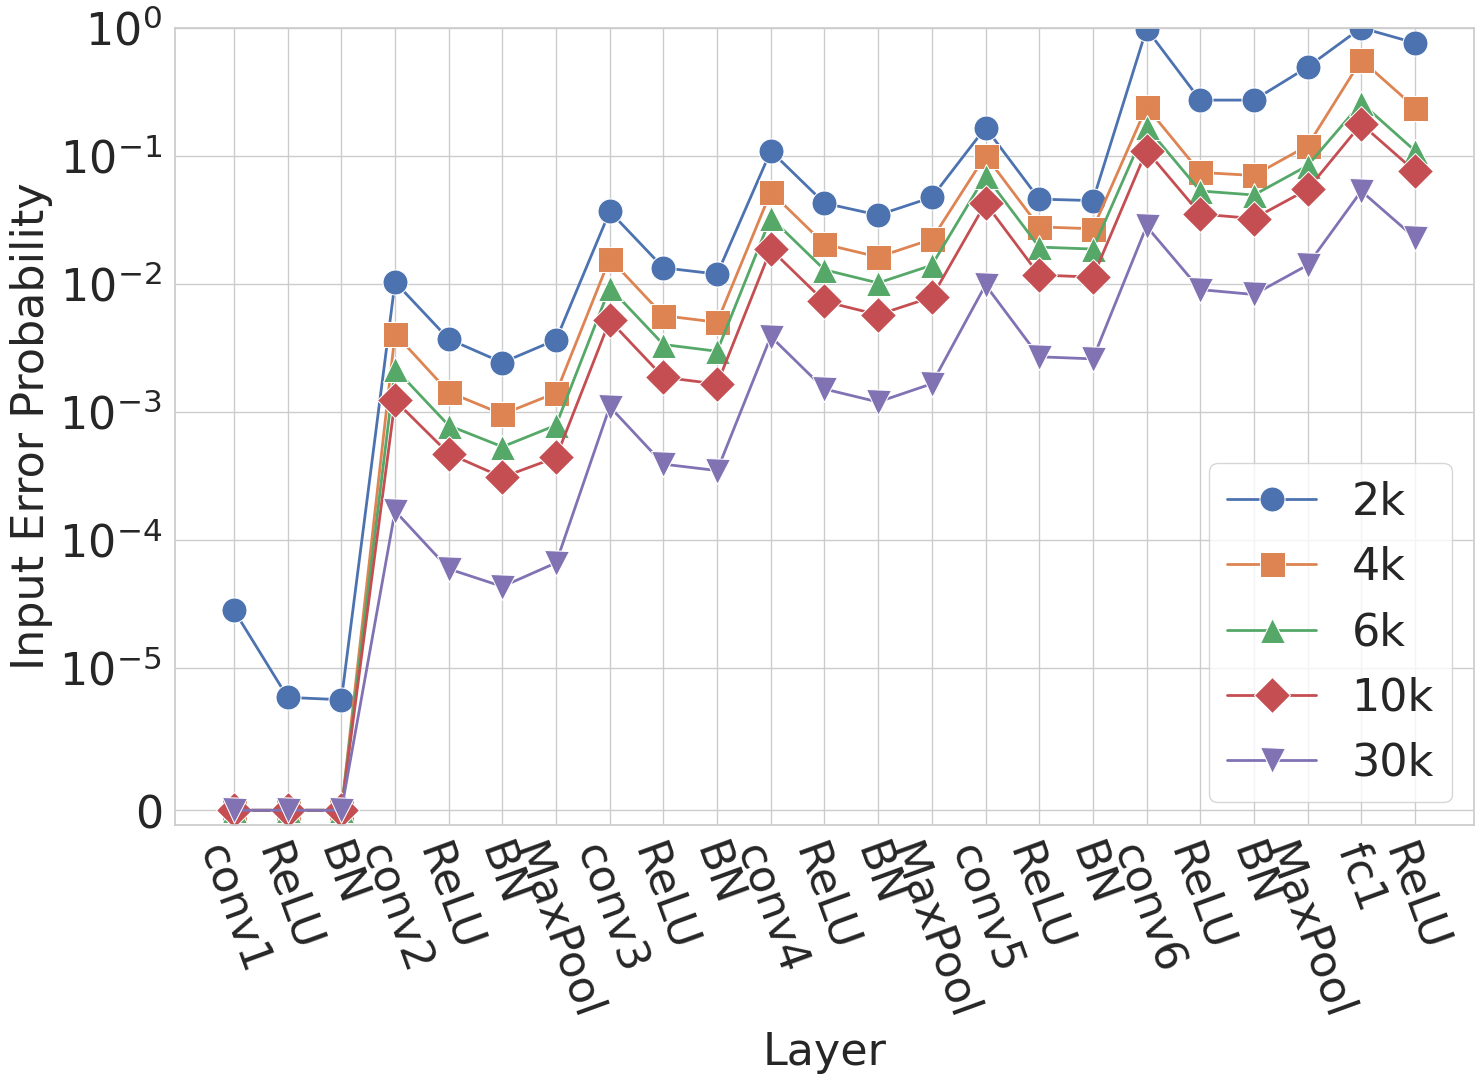

In [5]:
plot_pipeline_error_probabilities_seaborn(res_HD, num_traces, figsize=(15,11), font_size=32, save_name = 'input_err_prob_HD')

In [6]:
res_HW = [df[(df.leakage == 'HW') & (df.traces_k == k)].sort_values('stage_idx')['err_prob'].tolist() for k in num_traces]

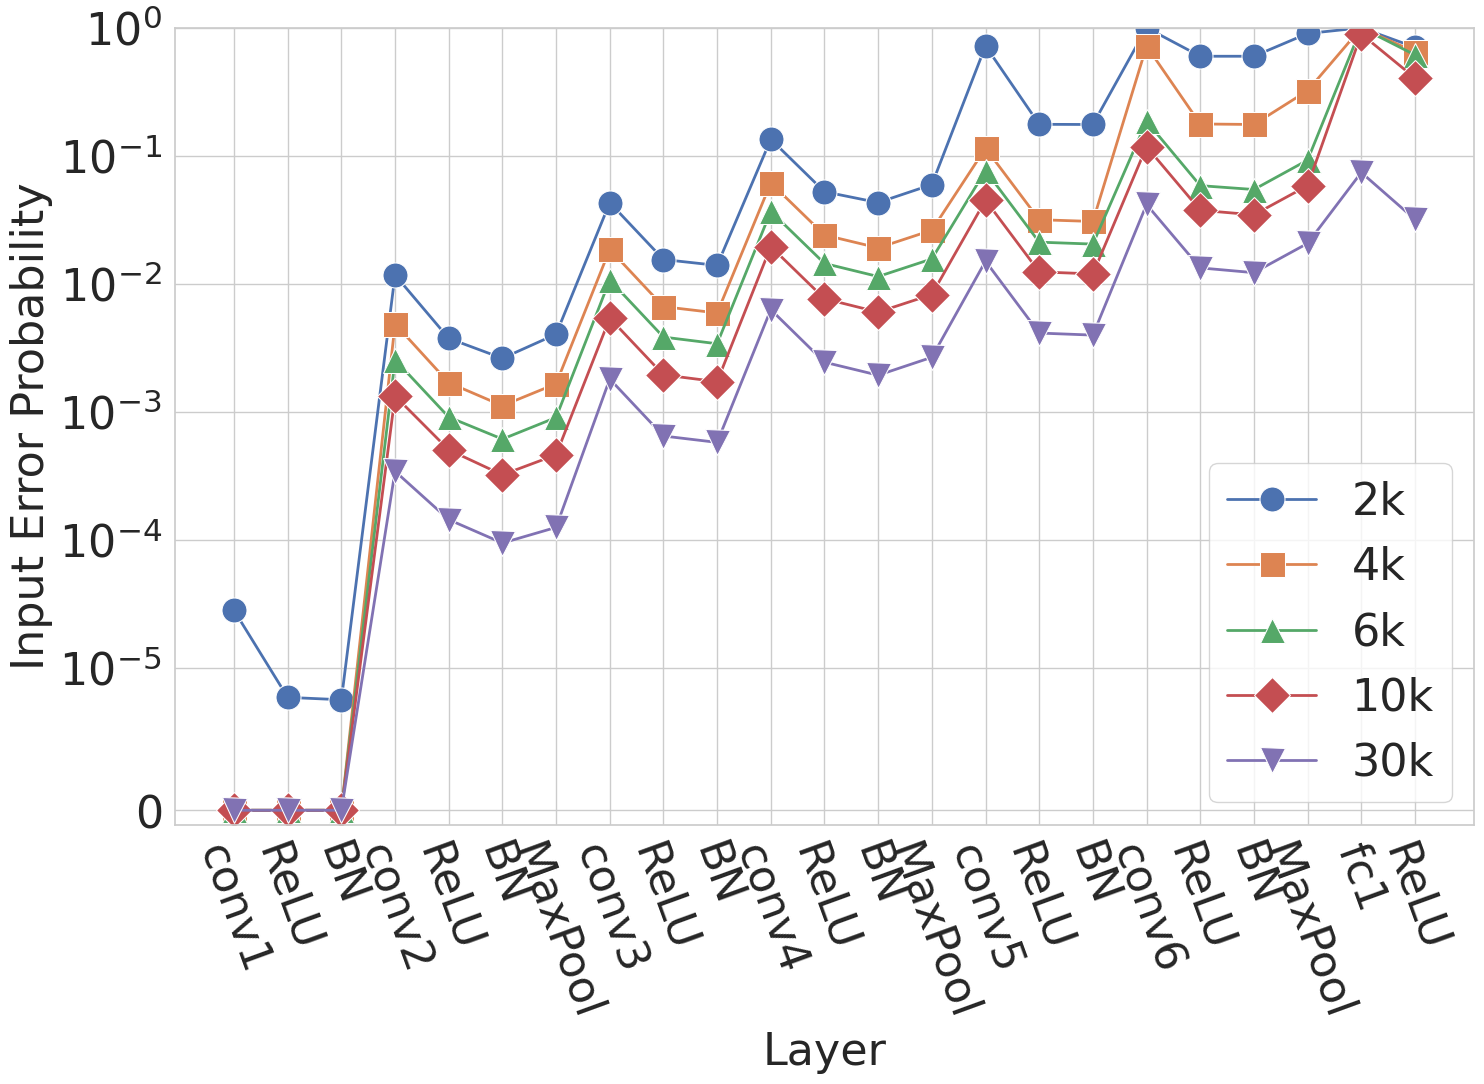

In [7]:
plot_pipeline_error_probabilities_seaborn(res_HW, num_traces, figsize=(15,11), font_size=32, save_name = 'input_err_prob_HW')